In [1]:
# Reference: https://herbie.readthedocs.io/en/stable/gallery/bonus_notebooks/time-height.html
from functions import *
from herbie import Herbie, FastHerbie, HerbieLatest
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import numpy as np
from datetime import datetime, timedelta


# Define the points of interest
cityName = "Louisville, KY (KSDF)"
points = pd.DataFrame({"longitude": [-85.735122], # 
                       "latitude":  [38.171471],  # Louisville, KY (KSDF)
                       })


# Generate a table of data

In [8]:
forecastInit = get_latest_forecast_cycle(model='HRRR')
# forecastInit = pd.Timestamp(2025, 3, 5, 18, 0)

# Use the function to calculate forecast range
forecastRange = calculate_forecast_range(forecastInit)

H = FastHerbie(
    [forecastInit],
    model="hrrr",
    product="sfc",
    fxx=forecastRange,
)

# 2m temperature
t2m_HRRR = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
                  ).herbie.pick_points(points, method="nearest"
                                       )['t2m'].sel(point=0)[1:]

t2m_HRRR = (t2m_HRRR - 273.15) * 1.8 + 32
t2m_max_HRRR = float(t2m_HRRR.max().values)
t2m_min_HRRR = float(t2m_HRRR.min().values)

model_init_HRRR = convert_time_to_datetime64(t2m_HRRR.time.values)
model_valid_times_HRRR = convert_time_to_datetime64(t2m_HRRR.valid_time.values)

# 10m wind speed
si10_HRRR = H.xarray(":WIND", backend_kwargs={'decode_times':False}
                     ).herbie.pick_points(points, method="nearest"
                                          )['si10'].sel(point=0)[1:]
si10_max_HRRR = float(si10_HRRR.max().values)
si10_max_HRRR = si10_max_HRRR * 1.94384  # Convert m/s to knots

# Total precipitation
tp_HRRR = H.xarray("APCP", backend_kwargs={'decode_times':False}
              ).herbie.pick_points(points, method="nearest"
                                   )['tp'].sel(point=0)
tp_HRRR = tp_HRRR * 0.0393701  # Convert mm (1 kg m^-2 = 1 mm) to inches
tp_HRRR = tp_HRRR[1:] - tp_HRRR[0]  # Subtract the total precipitation that falls before 06UTC
tp_max_HRRR = float(tp_HRRR.max().values)


## Make the table

# Create the title
title = f"Forecasting for {cityName} \nValid: {str(model_valid_times_HRRR[0])} - {str(model_valid_times_HRRR[-1])} UTC"
# {tomorrow.strftime('%B %d')} 06UTC - {day_after_tomorrow.strftime('%B %d')} 06UTC"

# Create the table
data = {
    "Model": ["HRRR"],  # "NBM"],
    "High (°F)": [t2m_max_HRRR],  # np.nan],  # Replace np.nan with actual values if available
    "Low (°F)": [t2m_min_HRRR],  # np.nan],   # Replace np.nan with actual values if available
    "Precipitation (in)": [tp_max_HRRR],  # np.nan],  # Replace np.nan with actual values if available
    "Wind Speed (kt)": [si10_max_HRRR],  # np.nan]  # Replace np.nan with actual values if available
    "Model Init": f" {str(model_init_HRRR)} UTC",  # np.nan]  # Replace np.nan with actual values if available
}

df_forecast = pd.DataFrame(data).round(2)

# Print the title and table without row numbers
print(title)
print(df_forecast.to_string(index=False))

Forecasting for Louisville, KY (KSDF) 
Valid: 2025-03-19T06 - 2025-03-20T05 UTC
Model  High (°F)  Low (°F)  Precipitation (in)  Wind Speed (kt)         Model Init
 HRRR      63.72      47.1                0.17            18.03  2025-03-18T18 UTC


In [17]:
forecastInit = get_latest_forecast_cycle(model='HRRR')
# forecastInit = pd.Timestamp(2025, 3, 5, 18, 0)

# Use the function to calculate forecast range
forecastRange = calculate_forecast_range(forecastInit)

H = FastHerbie(
    [forecastInit],
    model="hrrr",
    product="sfc",
    fxx=forecastRange,
)

# 2m temperature
t2m_HRRR = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
                  ).herbie.pick_points(points, method="nearest"
                                       )['t2m'].sel(point=0)[1:]


In [19]:
(t2m_HRRR - 273.15) * 1.8 + 32


<xarray.DataArray 't2m' (step: 24)> Size: 96B
array([34.6894  , 33.99237 , 33.403778, 32.851715, 32.167046, 31.883656,
       31.679804, 34.835625, 39.161438, 42.15818 , 44.8662  , 47.888924,
       50.777664, 53.21894 , 54.916878, 55.12298 , 54.5457  , 53.317486,
       50.421707, 48.824078, 48.79738 , 48.386383, 48.0179  , 47.869038],
      dtype=float32)
Coordinates:
    time                 int64 8B 1742493600
  * step                 (step) float64 192B 12.0 13.0 14.0 ... 33.0 34.0 35.0
    heightAboveGround    float64 8B 2.0
    latitude             float64 8B 38.18
    longitude            float64 8B 274.3
    valid_time           (step) float64 192B 1.743e+09 1.743e+09 ... 1.743e+09
    gribfile_projection  object 8B None
    point_grid_distance  float64 8B 0.6257
    point_longitude      float64 8B -85.74
    point_latitude       float64 8B 38.17

# Generate a map

In [20]:
forecastInit = get_latest_forecast_cycle(model='HRRR')

# Use the function to calculate forecast range
forecastRange = calculate_forecast_range(forecastInit)

H = FastHerbie(
    [forecastInit],
    model="hrrr",
    product="sfc",
    fxx=forecastRange,
)

t2m_HRRR = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
                  )['t2m'][1:]
t2m_HRRR


<xarray.DataArray 't2m' (step: 24, y: 1059, x: 1799)> Size: 183MB
array([[[291.7691 , 291.7691 , 291.7691 , ..., 297.3941 , 297.4566 ,
         297.4566 ],
        [291.7691 , 291.7066 , 291.7066 , ..., 297.3941 , 297.3941 ,
         297.3941 ],
        [291.7691 , 291.7066 , 291.7066 , ..., 297.3316 , 297.3316 ,
         297.3941 ],
        ...,
        [280.7691 , 280.7691 , 280.7691 , ..., 272.2066 , 272.1441 ,
         272.1441 ],
        [280.7691 , 280.7691 , 280.7691 , ..., 272.2066 , 272.1441 ,
         272.1441 ],
        [280.7066 , 280.7066 , 280.7066 , ..., 272.1441 , 272.1441 ,
         272.1441 ]],

       [[291.69437, 291.69437, 291.69437, ..., 297.38187, 297.38187,
         297.38187],
        [291.69437, 291.63187, 291.63187, ..., 297.31937, 297.31937,
         297.38187],
        [291.69437, 291.63187, 291.63187, ..., 297.31937, 297.31937,
         297.38187],
...
        [280.61133, 280.61133, 280.61133, ..., 272.61133, 272.61133,
         272.54883],
        [280.61133, 280.61133, 280.61133, ..., 272.61133, 272.54883,
         272.54883],
        [280.61133, 280.61133, 280.61133, ..., 272.54883, 272.54883,
         272.54883]],

       [[291.15363, 291.15363, 291.09113, ..., 297.59113, 297.59113,
         297.59113],
        [291.15363, 291.02863, 291.02863, ..., 297.46613, 297.52863,
         297.52863],
        [291.09113, 291.02863, 291.02863, ..., 297.46613, 297.46613,
         297.52863],
        ...,
        [280.52863, 280.52863, 280.52863, ..., 272.52863, 272.52863,
         272.52863],
        [280.59113, 280.52863, 280.52863, ..., 272.52863, 272.52863,
         272.52863],
        [280.59113, 280.59113, 280.59113, ..., 272.52863, 272.52863,
         272.52863]]], dtype=float32)
Coordinates:
    time                 int64 8B 1742493600
  * step                 (step) float64 192B 12.0 13.0 14.0 ... 33.0 34.0 35.0
    heightAboveGround    float64 8B 2.0
    latitude             (y, x) float64 15MB 21.14 21.15 21.15 ... 47.85 47.84
    longitude            (y, x) float64 15MB 237.3 237.3 237.3 ... 299.0 299.1
    valid_time           (step) float64 192B 1.743e+09 1.743e+09 ... 1.743e+09
    gribfile_projection  object 8B None
Dimensions without coordinates: y, x
Attributes: (12/37)
    GRIB_paramId:                             167
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      1905141
    GRIB_typeOfLevel:                         heightAboveGround
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_shortName:                           2t
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            air_temperature
    grid_mapping:                             gribfile_projection

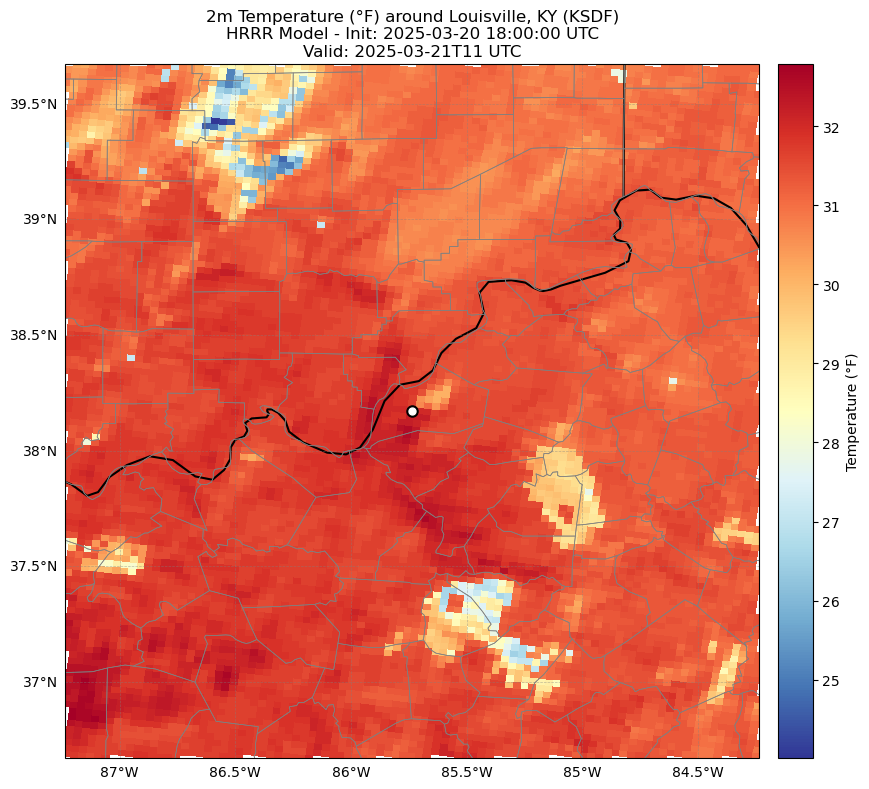

In [21]:
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patches as mpatches

# Get the regional data
plot_data = sel_region(t2m_HRRR, center=points.values[0], width=3)[5]

# Convert Kelvin to Fahrenheit
plot_data_F = (plot_data - 273.15) * 1.8 + 32

# Create figure with projection
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# Set extent based on the points
lon, lat = points.values[0]
ax.set_extent([lon-1.5, lon+1.5, lat-1.5, lat+1.5], crs=ccrs.PlateCarree())

# Plot the temperature data
mesh = ax.pcolormesh(
    plot_data_F.longitude, 
    plot_data_F.latitude, 
    plot_data_F.values, 
    transform=ccrs.PlateCarree(),
    cmap='RdYlBu_r',
    shading='auto'
)

# Add a colorbar
cbar = plt.colorbar(mesh, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('Temperature (°F)')

# Add state boundaries
states = cfeature.NaturalEarthFeature(
    category='cultural',
    name='admin_1_states_provinces_lines',
    scale='50m',
    facecolor='none'
)
ax.add_feature(states, edgecolor='black', linewidth=1.5)

# Add county boundaries
counties = cfeature.NaturalEarthFeature(
    category='cultural',
    name='admin_2_counties',
    scale='10m',
    facecolor='none'
)
ax.add_feature(counties, edgecolor='gray', linewidth=0.5)

# Add a marker for Louisville
ax.plot(lon, lat, 'ko', markersize=8, transform=ccrs.PlateCarree())
ax.plot(lon, lat, 'wo', markersize=5, transform=ccrs.PlateCarree())

# Add gridlines
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

# Add title
valid_time = convert_time_to_datetime64(plot_data.valid_time.values)
plt.title(f"2m Temperature (°F) around {cityName}\nHRRR Model - Init: {forecastInit} UTC\nValid: {valid_time} UTC", fontsize=12)

plt.tight_layout()
plt.show()




In [ ]:
from IPython.display import HTML

import matplotlib.pyplot as plt
import matplotlib.animation as animation
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
import numpy as np
import os

# Create a custom colormap centered at 32°F (freezing point)
# Blue colors for below freezing, red colors for above freezing
cmap = plt.cm.RdBu_r
norm = mcolors.TwoSlopeNorm(vmin=20, vcenter=32, vmax=60)

# Create figure with projection
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# Set extent based on the points
lon, lat = points.values[0]
ax.set_extent([lon-1.5, lon+1.5, lat-1.5, lat+1.5], crs=ccrs.PlateCarree())

# Add state boundaries
states = cfeature.NaturalEarthFeature(
    category='cultural',
    name='admin_1_states_provinces_lines',
    scale='50m',
    facecolor='none'
)
ax.add_feature(states, edgecolor='black', linewidth=1.5)

# Add county boundaries
counties = cfeature.NaturalEarthFeature(
    category='cultural',
    name='admin_2_counties',
    scale='10m',
    facecolor='none'
)
ax.add_feature(counties, edgecolor='gray', linewidth=0.5)

# Add a marker for Louisville
ax.plot(lon, lat, 'ko', markersize=8, transform=ccrs.PlateCarree())
ax.plot(lon, lat, 'wo', markersize=5, transform=ccrs.PlateCarree())

# Add gridlines
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

# Initialize mesh
regional_data = sel_region(t2m_HRRR, center=points.values[0], width=3)
data_F = (regional_data[0] - 273.15) * 1.8 + 32
mesh = ax.pcolormesh(
    data_F.longitude, 
    data_F.latitude, 
    data_F.values, 
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    shading='auto'
)

# Add a colorbar
cbar = plt.colorbar(mesh, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('Temperature (°F)')
# Add a line at 32°F
cbar.ax.axhline(y=cbar.norm(32.0), color='k', linestyle='-', linewidth=1)
cbar.ax.text(1.1, cbar.norm(32.0), 'Freezing', fontsize=8, va='center')


# Title placeholder - will be updated in animation
title = ax.set_title('')

# Animation function
def animate(frame_num):
    data_F = (regional_data[frame_num] - 273.15) * 1.8 + 32
    mesh.set_array(data_F.values.ravel())
    valid_time = convert_time_to_datetime64(regional_data[frame_num].valid_time.values)
    title.set_text(f"2m Temperature (°F) around {cityName}\nHRRR Model - Init: {forecastInit} UTC\nValid: {valid_time} UTC")
    return mesh,

# Create animation
ani = animation.FuncAnimation(
    fig, 
    animate, 
    frames=len(regional_data),
    interval=500,  # milliseconds between frames
    blit=False
)

# Save the animation
save_path = "/Users/jglarson/Documents/Website/WeatherFigures"
os.makedirs(save_path, exist_ok=True)
filename = os.path.join(save_path, f"temp_animation_{forecastInit.strftime('%Y%m%d%H')}.mp4")

try:
    # Try to use ffmpeg writer with explicit path
    Writer = animation.writers['ffmpeg']
    writer = Writer(fps=2, metadata=dict(artist='Me'), bitrate=1800)
    ani.save(filename, writer=writer, dpi=200)
    print(f"Animation saved to {filename}")
except Exception as e:
    print(f"Could not save animation with ffmpeg: {e}")
    
    # Try to save as GIF instead
    gif_filename = os.path.join(save_path, f"temp_animation_{forecastInit.strftime('%Y%m%d%H')}.gif")
    try:
        ani.save(gif_filename, writer='pillow', fps=2, dpi=100)
        print(f"Animation saved as GIF to {gif_filename}")
    except Exception as e2:
        print(f"Could not save animation as GIF either: {e2}")
        
        # If all else fails, just display in notebook
        print("Animation will only be displayed in notebook")

# Display the animation in notebook
plt.close()  # Prevent the static plot from displaying
HTML(ani.to_jshtml())

Could not save animation with ffmpeg: Requested MovieWriter (ffmpeg) not available


posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and pos

Animation saved as GIF to /Users/jglarson/Documents/Website/WeatherFigures/temp_animation_2025032018.gif


posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and pos

In [ ]:
# Total precipitation
tp_HRRR = H.xarray("APCP", backend_kwargs={'decode_times':False}
              )['tp']
tp_HRRR = tp_HRRR * 0.0393701  # Convert mm (1 kg m^-2 = 1 mm) to inches
tp_HRRR = tp_HRRR[1:] - tp_HRRR[0]  # Subtract the total precipitation that falls before 06UTC
tp_max_HRRR = float(tp_HRRR.max().values)

plot_data = sel_region(t2m_HRRR, center=points.values[0], width=3)


In [27]:
tp_HRRR

<xarray.DataArray 'tp' (step: 24, y: 1059, x: 1799)> Size: 183MB
array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
...
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]], dtype=float32)
Coordinates:
    time                 int64 8B 1742493600
  * step                 (step) float64 192B 12.0 13.0 14.0 ... 33.0 34.0 35.0
    surface              float64 8B 0.0
    latitude             (y, x) float64 15MB 21.14 21.15 21.15 ... 47.85 47.84
    longitude            (y, x) float64 15MB 237.3 237.3 237.3 ... 299.0 299.1
    gribfile_projection  object 8B None
Dimensions without coordinates: y, x

# ECMWF

In [9]:
forecastInit = get_latest_forecast_cycle(model='ECMWF')

# Use the function to calculate forecast range
forecastRange = calculate_forecast_range(forecastInit)

H = FastHerbie(
    [forecastInit],
    model="ifs",
    product="oper",
    fxx=forecastRange,
)

# Test if the forecast is available
# H.inventory(":2t:.*fcst:nan")

# 2m temperature
t2m_IFS = H.xarray(":2t:", backend_kwargs={'decode_times':False}
                  ).herbie.pick_points(points, method="nearest"
                                       )['t2m'].sel(point=0)

t2m_IFS = (t2m_IFS - 273.15) * 1.8 + 32
t2m_max_IFS = float(t2m_IFS.max().values)
t2m_min_IFS = float(t2m_IFS.min().values)

model_init_IFS = convert_time_to_datetime64(t2m_IFS.time.values)
model_valid_times_IFS = convert_time_to_datetime64(t2m_IFS.valid_time.values)

# 10m wind speed
u10_IFS = H.xarray(":10u:", backend_kwargs={'decode_times':False}
                     ).herbie.pick_points(points, method="nearest"
                                          )['u10'].sel(point=0)
v10_IFS = H.xarray(":10v:", backend_kwargs={'decode_times':False}
                     ).herbie.pick_points(points, method="nearest"
                                          )['v10'].sel(point=0)
# Calculate max wind speed from u and v components
si10_max_IFS = float((np.sqrt(u10_IFS**2 + v10_IFS**2)).max().values)
si10_max_IFS = si10_max_IFS * 1.94384  # Convert m/s to knots

# Total precipitation
tp_IFS = H.xarray(":tp:", backend_kwargs={'decode_times':False}
                     ).herbie.pick_points(points, method="nearest"
                                          )['tp'].sel(point=0)
tp_sum_IFS = float(tp_IFS.sum().values)


# Make the table


# Create the title
title = f"Forecasting for {cityName} - Model initialized {str(model_init_IFS)} UTC\nValid: {str(model_valid_times_IFS[0])} - {str(model_valid_times_IFS[-1])} UTC"
# {tomorrow.strftime('%B %d')} 06UTC - {day_after_tomorrow.strftime('%B %d')} 06UTC"

# Create the table
data = {
    "Model": ["ECMWF IFS"],
    "High (°F)": [t2m_max_IFS],
    "Low (°F)": [t2m_min_IFS],
    "Precipitation (in)": [tp_sum_IFS],
    "Wind Speed (kt)": [si10_max_IFS],
}

df_forecast = pd.DataFrame(data).round(2)

# Print the title and table without row numbers
print(title)
print(df_forecast.to_string(index=False))



Could not find 17/8 GRIB files.


Forecasting for Louisville, KY (KSDF) - Model initialized 2025-03-18T12 UTC
Valid: 2025-03-19T06 - 2025-03-20T03 UTC
    Model  High (°F)  Low (°F)  Precipitation (in)  Wind Speed (kt)
ECMWF IFS      64.91     54.67                0.01            14.28


In [10]:
# Create the title
title = f"Forecasting for {cityName} \nValid: {str(model_valid_times_HRRR[0])} - {str(model_valid_times_HRRR[-1])} UTC"

# Create the table combining both models
data = {
    "Model": ["HRRR", "ECMWF IFS"],
    "High (°F)": [t2m_max_HRRR, t2m_max_IFS],
    "Low (°F)": [t2m_min_HRRR, t2m_min_IFS],
    "Precipitation (in)": [tp_max_HRRR, tp_sum_IFS],
    "Wind Speed (kt)": [si10_max_HRRR, si10_max_IFS],
    "Model Init": [f" {str(model_init_HRRR)} UTC", f" {str(model_init_IFS)} UTC"]
}

df_forecast = pd.DataFrame(data).round(2)

# Print the title and table without row numbers
print(title)
print(df_forecast.to_string(index=False))


Forecasting for Louisville, KY (KSDF) 
Valid: 2025-03-19T06 - 2025-03-20T05 UTC
    Model  High (°F)  Low (°F)  Precipitation (in)  Wind Speed (kt)         Model Init
     HRRR      63.72     47.10                0.17            18.03  2025-03-18T18 UTC
ECMWF IFS      64.91     54.67                0.01            14.28  2025-03-18T12 UTC


# ECMWF Ensemble Forecast

In [ ]:
# H = Herbie("2022-01-26 00:00", model="ifs", product="enfo")
# ds = H.xarray(":2t:")


# Generate a time series

In [22]:
# https://herbie.readthedocs.io/en/stable/gallery/noaa_models/hrrr.html
H = FastHerbie(
    [get_latest_forecast_cycle()],
    model="hrrr",
    product="sfc",
    fxx=list(range(6, 30)),
)

t2m_ds = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
                  ).herbie.pick_points(points, method="nearest")

t2m_ds = (t2m_ds['t2m'] - 273.15) * 1.8 + 32

# t2m_ds


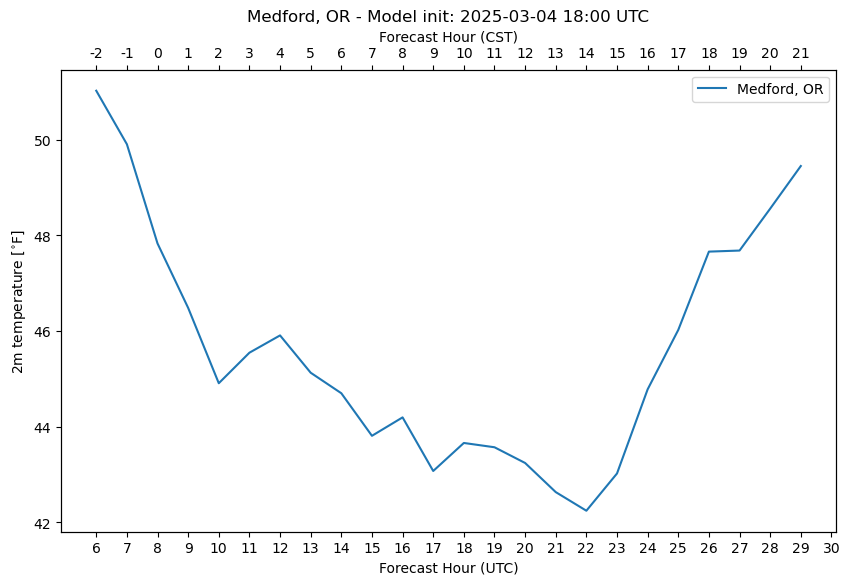

In [ ]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"{cityName} - Model init: {get_latest_forecast_cycle().strftime('%Y-%m-%d %H:%M')} UTC")

city2 = t2m_ds.sel(point=0).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,30), city2, label=cityName)
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel(r'2m temperature [$^{\circ}$F]')
ax1.set_xticks(np.arange(6,31))

# Create secondary x-axis for CST
ax2 = ax1.twiny()
cst_hours = np.arange(0,25)  # UTC-6
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(np.arange(6,30))
ax2.set_xticklabels([str(h-8) for h in range(6,30)])
ax2.set_xlabel('Forecast Hour (CST)')

# Annotate max and min for the city
max_wf = np.max(city2)
min_wf = np.min(city2)
max_wf_idx = np.argmax(city2)
min_wf_idx = np.argmin(city2)

plt.annotate(f'Max: {max_wf:.2f}', xy=(max_wf_idx + 6, max_wf), xytext=(max_wf_idx + 6, max_wf - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_wf:.2f}', xy=(min_wf_idx + 6, min_wf), xytext=(min_wf_idx + 6, min_wf + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))


# Add legend
ax1.legend()

plt.show()

## Precip

### To DO: Modify the tickmarks such that they update based on when the model was intialized

In [20]:
# Load in the data
H = FastHerbie(
    [get_latest_forecast_cycle()],
    model="hrrr",
    product="sfc",
    fxx=list(range(5, 30)),
)
                
tp = H.xarray("APCP", backend_kwargs={'decode_times':False}
              ).herbie.pick_points(points, method="nearest"
                                   )['tp']
tp = tp * 0.0393701  # Convert mm (1 kg m^-2 = 1 mm) to inches
tp = tp[1:] - tp[0]  # Subtract the total precipitation that falls before 06UTC
tp


<xarray.DataArray 'tp' (step: 24, point: 1)> Size: 96B
array([[0.00047244],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00594489]], dtype=float32)
Coordinates:
    time                 int64 8B 1741132800
  * step                 (step) float64 192B 6.0 7.0 8.0 9.0 ... 27.0 28.0 29.0
    surface              float64 8B 0.0
    latitude             (point) float64 8B 42.36
    longitude            (point) float64 8B 237.1
    gribfile_projection  object 8B None
    point_grid_distance  (point) float64 8B 1.457
    point_longitude      (point) float64 8B -122.9
    point_latitude       (point) float64 8B 42.37
Dimensions without coordinates: point

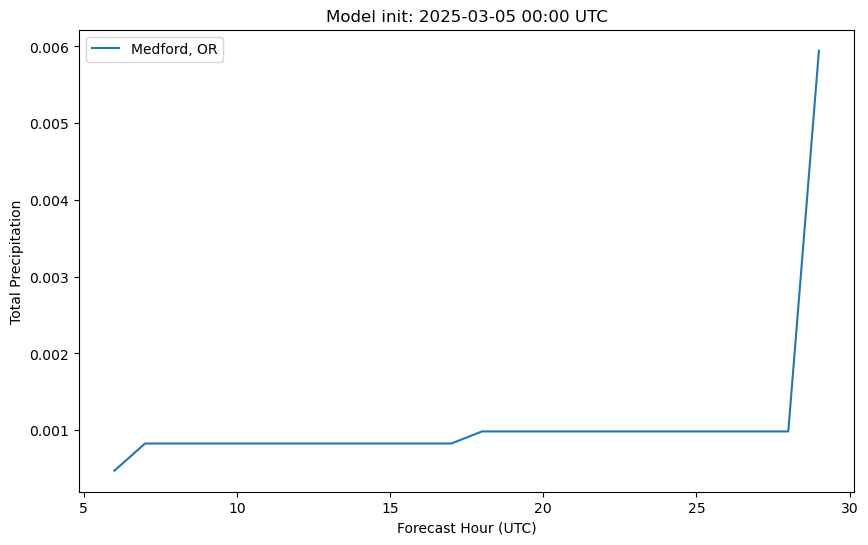

In [22]:

# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"Model init: {get_latest_forecast_cycle().strftime('%Y-%m-%d %H:%M')} UTC")

city2 = tp.sel(point=0).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,30), city2, label='Medford, OR')
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel('Total Precipitation')

# Add legend
ax1.legend()

plt.show()


# TO DO: convert tp from Kg per square meter to inches. Potentially 0.039370079003585

# Add NBM

In [ ]:
# dates = pd.date_range("2024-11-21 18:00", periods=1, freq="1h")
today = pd.Timestamp.now().date()
dates = pd.DatetimeIndex([pd.Timestamp(f"{today} 18:00")])

H = FastHerbie(dates, model="nbm", fxx=list(range(6, 30)), product="co")
H.inventory(":TMP:2 m above ground:.*fcst:nan")

points = pd.DataFrame({"longitude": [-105.082396, -80.172745], # [Fort Collins, Erie]
                       "latitude": [40.548843, 42.083850],
                       })

ds = H.xarray(":TMP:2 m above ground:.*fcst:nan", backend_kwargs={'decode_times':False}
              ).herbie.pick_points(points, method="nearest")

t2m_ds = (ds['t2m'] - 273.15) * 1.8 + 32

👨🏻‍🏭 Created directory: [/Users/jglarson/data/nbm/20241227]


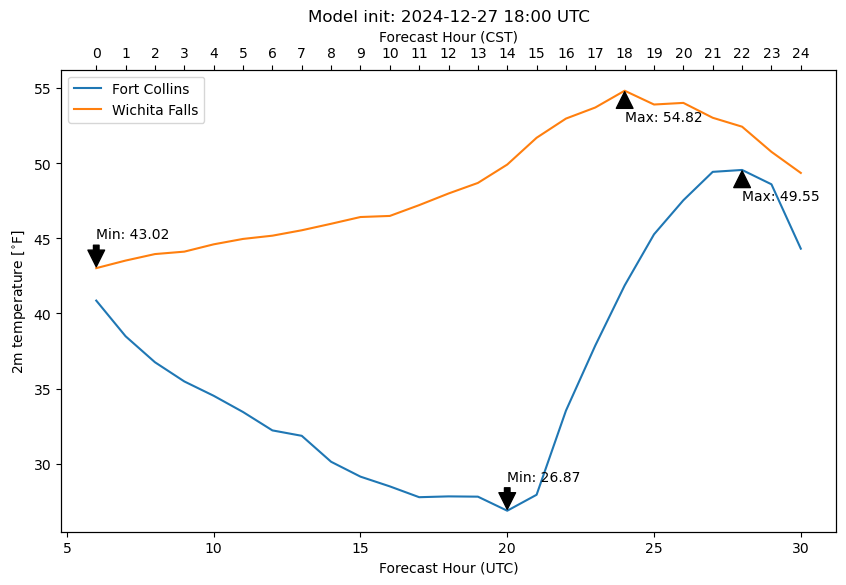

In [ ]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"Model init: {dates[0].strftime('%Y-%m-%d %H:%M')} UTC")

fort_collins = t2m_ds.sel(point=0).values
city2 = t2m_ds.sel(point=1).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,30), fort_collins, label='Fort Collins')
ax1.plot(np.arange(6,30), city2, label='Wichita Falls')
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel(r'2m temperature [$^{\circ}$F]')

# Create secondary x-axis for CST
ax2 = ax1.twiny()
cst_hours = np.arange(0,25)  # UTC-6
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(np.arange(6,30))
ax2.set_xticklabels([str(h-6) for h in range(6,30)])
ax2.set_xlabel('Forecast Hour (CST)')

# Annotate max and min for Fort Collins
max_fc = np.max(fort_collins)
min_fc = np.min(fort_collins)
max_fc_idx = np.argmax(fort_collins)
min_fc_idx = np.argmin(fort_collins)

plt.annotate(f'Max: {max_fc:.2f}', xy=(max_fc_idx + 6, max_fc), xytext=(max_fc_idx + 6, max_fc - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_fc:.2f}', xy=(min_fc_idx + 6, min_fc), xytext=(min_fc_idx + 6, min_fc + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))

# Annotate max and min for Wichita Falls
max_wf = np.max(city2)
min_wf = np.min(city2)
max_wf_idx = np.argmax(city2)
min_wf_idx = np.argmin(city2)

plt.annotate(f'Max: {max_wf:.2f}', xy=(max_wf_idx + 6, max_wf), xytext=(max_wf_idx + 6, max_wf - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_wf:.2f}', xy=(min_wf_idx + 6, min_wf), xytext=(min_wf_idx + 6, min_wf + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))


# Add legend
ax1.legend()

plt.show()